# [WEEK 7] A/B Test Design — Assignment (학생용)

**과제 유형: B. 도구 활용형** (생성형 AI 사용 가능, 판단·검증·해석은 직접)

## 과제 목적

숙박 예약 앱의 분석팀이 **"promotion 채널 사용자의 목록 → 상세 전환율이 유독 낮다"**는 진단을 넘겨줬습니다.
이번 과제에서는 이 문제를 개선할 아이디어를 **검증 가능한 실험으로 설계**하고, **여러분이 쓴 설계서 그대로 실험을 돌려** 결과를 판정합니다.

과제의 무게중심은 코드가 아니라 **설계**입니다. 설계서에 적은 값(지표, 배정 단위, 표본, 기간, 중단 규칙)이 실제 실험 결과를 결정하고, 결과를 보기 전에 정한 **판정 규칙**대로 배포 여부를 결정해야 합니다.

> **진단 메모 → 처방 선택 → 가설 → 지표 → 배정 → 표본·기간 → 사전 판정 규칙 → 실행 → SRM 확인 → 검정 → 판정**

---

## 📝 기술블로그 활용 안내

이번 글은 **"진단 결과를 받아서, 개선안을 실험으로 검증한다"**는 흐름으로 작성해주세요. 다음 그로스 세션 글과 이어지는 시리즈가 됩니다.

- **Part 0**의 Q0 답변 → 글의 도입부 ("왜 가격 표시 오류 수정은 실험하지 않고, 화면 개선만 실험했는가")
- **Part 1.2 ~ 1.7**의 설계서 → 본문 "실험 설계" 섹션 (특히 1.5의 MDE–기간 그래프와 선택 근거)
- **Part 2.2 ~ 2.3**의 결과 표·그래프와 결정 메모 → 본문 "결과와 의사결정" 섹션
- (선택) **Part 3** 심화 결과 → "설계가 달랐다면?" 섹션

코드를 나열하지 말고, **왜 그렇게 설계했고 결과를 어떻게 판정했는지**를 중심으로 써주세요.

---

## 🤖 생성형 AI 활용 안내

AI 사용은 가능합니다. 다만 이 과제는 **본인이 고른 설계값**(아이디어, 지표, 대상, 기간, 중단 규칙)에 따라 실험 결과가 달라지기 때문에, AI의 일반론으로는 답이 맞지 않습니다.

- 코드 문법, 시각화, 오류 수정, 개념 확인에 활용 가능
- 수치와 판정은 반드시 **본인 데이터로 직접 계산한 결과**로
- 마지막 셀에 **AI 활용 방법과 대화 내역**을 꼭 붙여주세요

> 이번 과제에서 가장 많이 감점되는 실수: **결과를 보고 나서 판정 기준을 바꾸는 것**입니다.

---
# 0. 환경 설정

1. 라이브러리 셀 → **실험 시뮬레이터** 셀 → **분석 도우미** 셀을 차례로 실행하세요. (세 셀 모두 수정하지 마세요)
2. 그다음 데이터 생성 셀을 실행하세요. `SEED`는 고정값이라 모두 같은 사용자 데이터를 씁니다.
   **결과를 다르게 만드는 건 여러분의 설계**입니다.

데이터는 교육용 synthetic dataset입니다. 가상의 숙박 예약 앱 로그이며, 이후 그로스 세션 과제에서도 같은 앱이 등장합니다.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [2]:
#@title ⚙️ 실험 시뮬레이터 — 수정하지 말고 실행하세요
# 이 셀은 "실험 전 로그"와 "여러분의 설계대로 돌아가는 A/B 실험 데이터"를 만들어 줍니다.
# 가상의 숙박 예약 앱 로그입니다. (이후 그로스 세션 과제에서도 같은 앱이 등장합니다)
import json, base64, math
import numpy as np
import pandas as pd

_CFG = json.loads(base64.b64decode(
    "eyJBIjogeyJkZXRhaWxfcHJvbW8iOiAwLjA0MiwgImRldGFpbF9vdGhlciI6IDAuMDA2LCAicm9vbSI6IDAuMDEs"
    "ICJyb29tX3Byb21vIjogMC4wMSwgImNvbXBsZXRlIjogMC4wLCAibm92ZWx0eSI6IDAuMCwgImFtb3VudCI6IDEu"
    "MCwgImNhbmNlbCI6IDAuMH0sICJCIjogeyJkZXRhaWxfcHJvbW8iOiAwLjA3LCAiZGV0YWlsX290aGVyIjogMC4w"
    "NDUsICJyb29tIjogLTAuMDY1LCAicm9vbV9wcm9tbyI6IC0wLjA2NSwgImNvbXBsZXRlIjogMC4wLCAibm92ZWx0"
    "eSI6IDAuMCwgImFtb3VudCI6IDEuMCwgImNhbmNlbCI6IDAuMH0sICJDIjogeyJkZXRhaWxfcHJvbW8iOiAwLjAx"
    "MiwgImRldGFpbF9vdGhlciI6IDAuMDA2LCAicm9vbSI6IDAuMCwgInJvb21fcHJvbW8iOiAwLjAsICJjb21wbGV0"
    "ZSI6IDAuMDMsICJub3ZlbHR5IjogMC4xLCAiYW1vdW50IjogMC45MiwgImNhbmNlbCI6IDAuMDR9fQ=="
).decode())

_CHANNELS = ["organic", "paid_search", "promotion", "referral"]
_CH_P = [0.38, 0.27, 0.20, 0.15]
_DEVICES = ["android", "ios", "web"]
_DV_P = [0.41, 0.38, 0.21]
_P_LIST = 0.925
_P_DETAIL = {"organic": 0.62, "paid_search": 0.60, "promotion": 0.49, "referral": 0.64}
_P_ROOM, _P_CHECKOUT = 0.66, 0.56
_PAY = {"ios": ([0.38, 0.12, 0.50]), "android": ([0.50, 0.15, 0.35]), "web": ([0.60, 0.18, 0.22])}
_METHODS = ["card", "bank_transfer", "simple_pay"]
_P_COMPLETE = {"card": 0.70, "bank_transfer": 0.66, "simple_pay": 0.69}
_POOL = 120_000                 # 앱 전체 활성 사용자
_DAILY_SESSIONS = 10_000        # 하루 검색 세션 (전체)
_EXP_START = pd.Timestamp("2026-03-02")
_CAMPAIGN_DAY = 8               # 실험 8일차부터 promotion 채널 대규모 광고 캠페인

METRICS = {
    # 지표 이름: (분자 컬럼, 분모 컬럼)  ※ 모두 "세션 단위 비율"
    "list_to_detail":       ("detail_view", "list_view"),
    "detail_to_room":       ("room_select", "detail_view"),
    "checkout_to_complete": ("payment_complete", "checkout"),
    "search_to_complete":   ("payment_complete", "search"),
    "cancel_rate":          ("cancelled", "payment_complete"),
    "revenue_per_search":   ("net_amount", "search"),
}


def _sig(x):
    return 1 / (1 + np.exp(-x))


def _logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def _users(rng):
    n = _POOL
    u = pd.DataFrame({
        "user_id": np.arange(200001, 200001 + n),
        "channel": rng.choice(_CHANNELS, size=n, p=_CH_P),
        "device": rng.choice(_DEVICES, size=n, p=_DV_P),
        "user_type": rng.choice(["leisure", "business"], size=n, p=[0.72, 0.28]),
    })
    # 방문 빈도(사람마다 다름)와 구매 성향(사람마다 다름)
    u["visit_rate"] = rng.gamma(0.5, 1.0, size=n)
    u["visit_rate"] *= _DAILY_SESSIONS / u["visit_rate"].sum()
    u["propensity"] = rng.normal(0, 1.0, size=n)
    u["old_browser"] = (u["device"] == "web") & (rng.random(n) < 0.45)
    u.loc[u["old_browser"], "propensity"] -= 0.6
    return u


def _simulate_sessions(rng, users, days, start, group=None, idea=None, target="promotion",
                       campaign_from=None, unit="user"):
    """days일 동안의 세션을 만든다. group: user_id -> 'A'/'B' (None이면 처치 없음)"""
    lam0 = users["visit_rate"].to_numpy()
    is_promo_user = (users["channel"] == "promotion").to_numpy()
    rows = []
    cfg = _CFG.get(idea, None) if idea else None
    for d in range(days):
        camp = campaign_from is not None and (d + 1) >= campaign_from
        lam = np.where(is_promo_user & camp, lam0 * 1.4, lam0)
        cnt = rng.poisson(lam)
        idx = np.repeat(np.arange(len(users)), cnt)
        if len(idx) == 0:
            continue
        s = users.iloc[idx].reset_index(drop=True)
        n = len(s)
        s["day"] = d + 1
        s["session_start"] = (start + pd.to_timedelta(d, unit="D")
                              + pd.to_timedelta(rng.integers(8 * 3600, 23 * 3600, size=n), unit="s"))
        # 처치 여부
        treat = np.zeros(n, dtype=bool)
        if group is not None:
            if unit == "session":
                in_exp = s["user_id"].isin(group.index).to_numpy()
                coin = rng.random(n) < 0.5
                s["group"] = np.where(in_exp, np.where(coin, "B", "A"), None)
            else:
                s["group"] = s["user_id"].map(group)
            treat = (s["group"] == "B").to_numpy()
        promo = (s["channel"] == "promotion").to_numpy()
        prop = s["propensity"].to_numpy()
        if camp:   # 캠페인으로 들어온 세션은 구매 의도가 상대적으로 약함
            prop = prop - np.where(promo, 0.35, 0.0)

        # 효과 크기 (세션 단위 배정이면 같은 사람이 두 화면을 오가며 효과가 일부 희석됨)
        dil = 0.8 if unit == "session" else 1.0
        e_detail = np.zeros(n); e_room = np.zeros(n); e_comp = np.zeros(n)
        if cfg is not None:
            nov = cfg["novelty"] * math.exp(-(d) / 4.0)
            e_detail = np.where(promo, cfg["detail_promo"] + nov, cfg["detail_other"] + nov * 0.5) * dil
            e_room = np.where(promo, cfg["room_promo"], cfg["room"]) * dil
            e_comp = np.full(n, cfg["complete"]) * dil
            e_detail *= treat; e_room *= treat; e_comp *= treat

        list_ = rng.random(n) < _P_LIST
        p_det = s["channel"].map(_P_DETAIL).to_numpy() + e_detail
        detail = list_ & (rng.random(n) < _sig(_logit(p_det) + prop))
        room = detail & (rng.random(n) < _sig(_logit(_P_ROOM + e_room) + 0.6 * prop))
        checkout = room & (rng.random(n) < _sig(_logit(np.full(n, _P_CHECKOUT)) + 0.4 * prop))
        dev = s["device"].to_numpy()
        pm = np.empty(n, dtype=object)
        for dv in _DEVICES:
            m = dev == dv
            pm[m] = rng.choice(_METHODS, size=m.sum(), p=_PAY[dv])
        pc = np.vectorize(_P_COMPLETE.get)(pm).astype(float) + np.where(dev == "web", 0.02, 0)
        bug = (dev == "ios") & (pm == "simple_pay")
        broken = bug & (s["session_start"] >= pd.Timestamp("2026-04-01")).to_numpy()
        pc = np.where(broken, 0.28, pc)
        complete = checkout & (rng.random(n) < np.clip(pc + e_comp, 0, 0.99))
        s["search"] = 1
        s["list_view"] = list_.astype(int)
        s["detail_view"] = detail.astype(int)
        s["room_select"] = room.astype(int)
        s["checkout"] = checkout.astype(int)
        s["payment_complete"] = complete.astype(int)
        s["payment_method"] = np.where(checkout, pm, None)
        acc = rng.choice(["hotel", "pension", "motel"], size=n, p=[0.5, 0.3, 0.2])
        mean_amt = pd.Series(acc).map({"hotel": 230_000, "pension": 175_000, "motel": 115_000}).to_numpy()
        amt = np.maximum(50_000, np.round(rng.normal(mean_amt, 40_000), -2))
        canc_p = np.full(n, 0.075)
        if cfg is not None:
            target_mask = promo if target == "promotion" else np.ones(n, dtype=bool)
            amt = np.where(treat & target_mask, np.round(amt * cfg["amount"], -2), amt)
            canc_p = np.where(treat, canc_p + cfg["cancel"], canc_p)
        s["amount"] = np.where(complete, amt, 0.0)
        s["cancelled"] = (complete & (rng.random(n) < canc_p)).astype(int)
        s["net_amount"] = np.where(s["cancelled"] == 1, 0.0, s["amount"])
        rows.append(s)
    out = pd.concat(rows, ignore_index=True)
    return out


def generate_pre_period(seed):
    """실험 직전 4주(2026-02-02 ~ 03-01)의 세션 로그. 기준선(baseline) 추정용"""
    rng = np.random.default_rng(seed)
    users = _users(rng)
    pre = _simulate_sessions(rng, users, 28, pd.Timestamp("2026-02-02"))
    pre = pre.drop(columns=["visit_rate", "propensity", "old_browser"])
    pre.insert(0, "session_id", [f"P{i:08d}" for i in range(len(pre))])
    return pre


def run_experiment(design, seed):
    """여러분의 설계(design)대로 실험을 돌려 세션 로그를 돌려줍니다."""
    need = ["idea", "target", "unit", "primary_metric", "guardrails", "alpha", "power",
            "mde_abs", "traffic_share", "duration_days", "stopping"]
    miss = [k for k in need if k not in design]
    if miss:
        raise ValueError(f"설계서에 빠진 항목이 있어요: {miss}")
    if design["idea"] not in ("A", "B", "C"):
        raise ValueError("idea는 'A', 'B', 'C' 중 하나예요")
    if design["primary_metric"] not in METRICS:
        raise ValueError(f"primary_metric은 {list(METRICS)} 중 하나예요")
    D = int(design["duration_days"])
    if not 3 <= D <= 42:
        raise ValueError("duration_days는 3~42일 사이로 정해주세요")

    rng = np.random.default_rng(seed)
    users = _users(rng)
    rng = np.random.default_rng(seed * 7919 + 17)
    eligible = users if design["target"] == "all" else users[users["channel"] == "promotion"]
    share = float(design["traffic_share"])
    eligible = eligible[rng.random(len(eligible)) < share]
    grp = pd.Series(np.where(rng.random(len(eligible)) < 0.5, "A", "B"), index=eligible["user_id"].to_numpy())

    sim_users = users[users["user_id"].isin(grp.index)]
    s = _simulate_sessions(rng, sim_users, D, _EXP_START, group=grp, idea=design["idea"],
                           target=design["target"], campaign_from=_CAMPAIGN_DAY, unit=design["unit"])

    # --- 데이터 수집 파이프라인 (실무에서 흔한 문제가 섞여 있을 수 있음) ---
    if design["idea"] == "B":
        lost = (s["group"] == "B") & s["old_browser"]
        lost_users = s.loc[lost, "user_id"].unique()
        drop_users = pd.Series(lost_users).sample(frac=0.95, random_state=seed).to_numpy()
        s = s[~s["user_id"].isin(drop_users)]

    # --- 중간 확인 후 중단 규칙 ---
    stopped = D
    if design["stopping"] == "peek":
        num, den = METRICS[design["primary_metric"]]
        for day in range(3, D + 1):
            sub = s[s["day"] <= day]
            a = sub[sub["group"] == "A"]; b = sub[sub["group"] == "B"]
            xa, na, xb, nb = a[num].sum(), a[den].sum(), b[num].sum(), b[den].sum()
            if min(na, nb) == 0:
                continue
            p = (xa + xb) / (na + nb)
            se = math.sqrt(p * (1 - p) * (1 / na + 1 / nb))
            z = (xb / nb - xa / na) / se if se > 0 else 0
            pval = 2 * (1 - 0.5 * (1 + math.erf(abs(z) / math.sqrt(2))))
            if pval < design["alpha"]:
                stopped = day
                break
        s = s[s["day"] <= stopped]

    s = s.drop(columns=["visit_rate", "propensity", "old_browser"]).reset_index(drop=True)
    s.insert(0, "session_id", [f"E{i:08d}" for i in range(len(s))])
    first = s.groupby("user_id")["session_start"].min()
    print(f"실험 기간: {_EXP_START.date()} ~ {(_EXP_START + pd.Timedelta(days=stopped - 1)).date()} "
          f"({stopped}일{' · 중간 확인 규칙으로 조기 종료' if stopped < D else ''})")
    print(f"실험에 노출된 사용자: {s['user_id'].nunique():,}명 / 세션: {len(s):,}개")
    print(f"참고: 실험 {_CAMPAIGN_DAY}일차({(_EXP_START + pd.Timedelta(days=_CAMPAIGN_DAY - 1)).date()})부터 마케팅팀의 promotion 채널 대규모 광고 캠페인이 시작됐습니다.")
    return s

In [3]:
#@title 🧰 분석 도우미 함수 — 수정하지 말고 실행하세요
from scipy import stats

def ratio_test(df, metric, alpha=0.05):
    """세션 단위 비율 지표를 A/B로 비교합니다.
    - naive : 세션 하나하나를 독립 관측으로 보고 계산한 표준오차
    - delta : 같은 사용자의 세션끼리 묶어서(사용자 단위) 계산한 표준오차 (Delta Method)
    """
    num, den = METRICS[metric]
    res = {}
    for g in ["A", "B"]:
        d = df[df["group"] == g]
        u = d.groupby("user_id")[[num, den]].sum()
        X, Y = u[num].to_numpy(float), u[den].to_numpy(float)
        n = len(u)
        R = X.sum() / Y.sum()
        var_delta = (X.var(ddof=1) - 2 * R * np.cov(X, Y, ddof=1)[0, 1] + R ** 2 * Y.var(ddof=1)) / (Y.mean() ** 2) / n
        sel = d[den].to_numpy(float) > 0
        per_session = d[num].to_numpy(float)[sel] / d[den].to_numpy(float)[sel]
        var_naive = per_session.var(ddof=1) / sel.sum()
        res[g] = dict(value=R, var_delta=var_delta, var_naive=var_naive, users=n, denom=Y.sum())
    diff = res["B"]["value"] - res["A"]["value"]
    se_d = np.sqrt(res["A"]["var_delta"] + res["B"]["var_delta"])
    se_n = np.sqrt(res["A"]["var_naive"] + res["B"]["var_naive"])
    z = stats.norm.ppf(1 - alpha / 2)
    return pd.Series({
        "metric": metric,
        "A": res["A"]["value"], "B": res["B"]["value"],
        "diff": diff, "rel_diff": diff / res["A"]["value"],
        "ci_low": diff - z * se_d, "ci_high": diff + z * se_d,
        "p_value": 2 * (1 - stats.norm.cdf(abs(diff / se_d))),
        "se_delta": se_d, "se_naive": se_n,
        "p_naive": 2 * (1 - stats.norm.cdf(abs(diff / se_n))),
    })


def aa_split(df, seed=0):
    """실험 전 데이터를 사용자 단위로 무작위 반반 나눠 가짜 A/B 그룹을 붙입니다 (A/A 테스트용)."""
    rng = np.random.default_rng(seed)
    users = df["user_id"].unique()
    g = pd.Series(np.where(rng.random(len(users)) < 0.5, "A", "B"), index=users)
    return df.assign(group=df["user_id"].map(g))

In [4]:
SEED = 73   # 모두 같은 값입니다. 수정하지 마세요.

pre = generate_pre_period(SEED)
print("실험 전 4주 세션 로그:", pre.shape)
display(pre.head())

실험 전 4주 세션 로그: (279534, 17)


,session_id,user_id,channel,device,user_type,day,session_start,search,list_view,detail_view,room_select,checkout,payment_complete,payment_method,amount,cancelled,net_amount
0,P00000000,200011,organic,ios,leisure,1,2026-02-02 13:58:36,1,1,1,1,1,0,card,0.0000,0,0.0000
1,P00000001,200024,organic,web,business,1,2026-02-02 22:56:10,1,1,1,1,1,0,simple_pay,0.0000,0,0.0000
2,P00000002,200056,promotion,web,leisure,1,2026-02-02 08:24:30,1,1,0,0,0,0,None,0.0000,0,0.0000
3,P00000003,200064,paid_search,ios,business,1,2026-02-02 15:55:17,1,1,0,0,0,0,None,0.0000,0,0.0000
4,P00000004,200064,paid_search,ios,business,1,2026-02-02 19:10:07,1,1,0,0,0,0,None,0.0000,0,0.0000


## 데이터 구조 — `pre` (실험 전 4주, 1 row = 1 session)

| column | description |
|---|---|
| `session_id`, `user_id` | 세션 ID, 사용자 ID |
| `channel`, `device`, `user_type` | 사용자 속성 |
| `day`, `session_start` | 기간 내 일차(1~28), 세션 시작 시각 |
| `search` ~ `payment_complete` | 각 퍼널 단계 도달 여부 (0/1) |
| `payment_method` | 결제수단 (checkout 이전에는 결측) |
| `amount`, `cancelled`, `net_amount` | 결제금액, 취소 여부, 취소 제외 금액 |

실험 데이터(Part 2)는 여기에 `group` 컬럼(A = 대조군, B = 실험군)이 추가됩니다.

---
# Part 0. 상황 브리핑 — 무엇을 실험할 것인가?

2026년 2월, 분석팀이 퍼널을 채널별로 쪼개 보다가 이런 메모를 남겼습니다.

> **분석팀 메모**
> promotion(광고·프로모션) 채널로 들어온 사용자는 **목록 → 상세 전환율**이 다른 채널보다 10%p가량 낮다.
> 다른 퍼널 단계는 채널 간 차이가 거의 없다. 최근에 갑자기 나빠진 게 아니라 원래부터 낮은 상태다.

같은 주에 QA팀에서도 이슈가 올라왔습니다.

> **QA팀 이슈**
> 일부 숙소의 상세 페이지 가격이 세금·봉사료가 빠진 금액으로 표시되고, 결제 화면에서야 최종 금액이 나온다.
> 총액 표시 의무 위반 소지가 있다.

팀은 두 가지 처방을 준비했습니다.

- **처방 ①** 상세 페이지 가격 표시 오류 수정 (총액 표시)
- **처방 ②** promotion 유입 사용자의 목록 → 상세 전환을 높이는 화면 개선

먼저 실험 전 데이터로 분석팀 메모가 맞는지 확인하세요.

In [6]:
# [0-A] 채널별 목록 → 상세 전환율 (세션 단위)
# 힌트: 분자 = 상세 진입 세션 수, 분모 = 목록 진입 세션 수

channel_l2d = (
    pre.groupby("channel")
       .agg(list_sessions=("list_view", "sum"), detail_sessions=("detail_view", "sum"))
)
channel_l2d["list_to_detail"] = channel_l2d["detail_sessions"] / channel_l2d["list_sessions"]
display(channel_l2d.sort_values("list_to_detail"))

# [0-B] 채널별 퍼널 단계 전환율 — 목록→상세 말고 다른 단계에도 차이가 있는지 확인
steps = ["search", "list_view", "detail_view", "room_select", "checkout", "payment_complete"]
f = pre.groupby("channel")[steps].sum()
step_rates = pd.DataFrame({f"{a} → {b}": f[b] / f[a] for a, b in zip(steps[:-1], steps[1:])})
display(step_rates.round(3))

,list_sessions,detail_sessions,list_to_detail
channel,,,
promotion,52906,25408,0.4802
paid_search,69715,40094,0.5751
organic,97392,57318,0.5885
referral,38385,23229,0.6052


,search → list_view,list_view → detail_view,detail_view → room_select,room_select → checkout,checkout → payment_complete
channel,,,,,
organic,0.9240,0.5890,0.6910,0.6030,0.6980
paid_search,0.9260,0.5750,0.6870,0.5990,0.6900
promotion,0.9250,0.4800,0.7000,0.6120,0.6910
referral,0.9220,0.6050,0.6880,0.5950,0.6930


### Q0. 무엇을 A/B 테스트할 것인가?

1. 처방 ①과 ② 중 **A/B 테스트가 필요한 것**은 무엇인가요? 나머지 하나는 어떻게 배포·검증하는 게 맞을까요?
2. 처방 ①을 A/B 테스트로 검증하면 어떤 문제가 생기나요? (사용자 경험, 법·윤리, 결정에 쓸 수 있는 정보 관점에서)
3. "A/B 테스트를 하지 않는다"고 해서 **아무것도 측정하지 않는 것**은 아닙니다. 처방 ①을 배포할 때 무엇을 모니터링해야 할까요?

**답변:**
1. 처방 ②는 어떤 화면 개선이 promotion 사용자의 전환을 얼마나 올릴지 불확실하고 개선안 후보도 여러 개라서, 실험으로 효과를 추정하고 비교해야 한다. 처방 ①은 총액 표시 의무 위반 소지가 있는 오류 수정이라서 실험 없이 전체 사용자에게 바로 배포하는 것이 맞다. 효과가 좋은지 나쁜지와 관계없이 수정은 해야 하는 일이다.


2. ①을 A/B 테스트하면 총액 표시 의무 위반 소지가 있다는 사실을 알고도 일부 사용자에게 잘못된 가격을 계속 표시하면 법적 문제가 발생할 수 있다.

3. 처방 ①을 배포한 뒤에는 상세 → 객실 선택 전환율, 체크아웃 → 결제완료 전환율, 취소율, 결제 화면 이탈률을 배포 전후로 모니터링한다.

---
# Part 1. 실험 설계서 (과제의 핵심)

이 Part에서 작성한 내용은 **결과를 보기 전의 약속**입니다. Part 2에서 결과를 본 뒤에는 Part 1을 수정하지 마세요.
(수정 이력은 Colab 버전 기록으로 확인할 수 있습니다)

## 1.1 개선 아이디어 선택

디자인팀이 promotion 유입 사용자를 위한 개선안 3개를 가져왔습니다. **하나를 골라** 실험하세요.

| 아이디어 | 내용 | 디자인팀의 근거 |
|---|---|---|
| **A** | 목록 화면 카드에 **프로모션 적용가(할인가)**를 표시 | 광고에서 본 할인가가 목록에 안 보여서 "광고랑 다르네" 하고 이탈한다 |
| **B** | 프로모션 대상 숙소를 **목록 최상단에 고정** | 프로모션으로 들어왔는데 해당 숙소를 찾기 어렵다 |
| **C** | 첫 방문 시 **할인 쿠폰 팝업** 노출 | 할인 혜택을 즉시 체감하게 하면 탐색이 늘어난다 |

- **선택한 아이디어:** C
- **선택 이유 (분석팀 메모와 0-B 결과에 연결해서 2~3문장):** 분석팀 메모와 0-B 결과에서 promotion 사용자의 병목은 목록 → 상세 단계 하나다. 이 단계의 전환율이 0.4802로 다른 채널(0.58~0.61)보다 10%p가량 낮고, 검색 → 목록이나 이후 단계는 채널 간 차이가 거의 없다. promotion 사용자는 할인을 기대하고 들어오므로 첫 진입에서 쿠폰 혜택을 바로 보여 주면 숙소를 열어 볼 동기가 생겨 목록 → 상세 전환이 오를 것이라고 판단했다.C는 혜택을 먼저 체감시켜 탐색 동기를 만드는 안이라 promotion 사용자 전체에 적용할 수 있다고 보고 C를 선택했다.
- **이 아이디어가 실패한다면 어떤 이유 때문일까? (예상되는 부작용 1개 이상):** 첫 방문자의 주된 목적이 할인이 아니라 숙소 탐색이면 팝업이 방해 요소가 되어 닫고 이탈할 수 있다.

## 1.2 가설 (Action → Behavior → Impact)

- **Action (무엇을 바꾸면):** promotion 채널로 유입된 사용자가 첫 방문할 때 할인 쿠폰 팝업을 노출하면
- **Behavior (사용자가 어떻게 행동해서):** 앱에 들어오자마자 쿠폰 혜택을 확인하고 이를 쓰려고 목록의 숙소 카드를 열어 보는 사용자가 늘어
- **Impact (어떤 지표가 어느 방향으로, 대략 얼마나):** promotion 사용자의 목록 → 상세 전환율(상세 진입 세션 ÷ 목록 진입 세션)이 현재 약 0.48에서 0.60 수준까지 오를 것이다. 0.60은 다른 채널(0.58~0.61)과 같은 수준이다.

> "사용성이 좋아질 것이다"처럼 측정할 수 없는 문장은 가설이 아닙니다.

## 1.3 지표 체계

이번 실험에 맞게 지표 체계를 설계하세요.
시뮬레이터가 계산할 수 있는 지표는 아래와 같습니다. (모두 **세션 단위 비율**)

| 지표 키 | 분자 | 분모 |
|---|---|---|
| `list_to_detail` | 상세 진입 세션 | 목록 진입 세션 |
| `detail_to_room` | 객실 선택 세션 | 상세 진입 세션 |
| `checkout_to_complete` | 결제완료 세션 | checkout 세션 |
| `search_to_complete` | 결제완료 세션 | 검색 세션 |
| `cancel_rate` | 취소된 예약 세션 | 결제완료 세션 |
| `revenue_per_search` | 취소 제외 결제금액 합 | 검색 세션 |


| 역할 | 지표 | 분자 / 분모 / Grain / Window | 왜 이 역할인가 |
|---|---|---|---|
| Primary (1개) | list_to_detail | 분자: 상세 진입 세션 / 분모: 목록 진입 세션 / Grain: 세션(배정은 사용자 단위, 분석은 사용자로 묶음) / Window: 실험 14일 전체 | 가설의 Impact이고, 진단된 병목 단계를 직접 겨냥한 지표다 |
| Guardrail (1개 이상) | revenue_per_search, search_to_complete | 분자: 취소 제외 결제금액 합, 결제완료 세션 / 분모: 검색 세션 / Grain: 세션 / Window: 14일 | 쿠폰 할인으로 매출이 나빠지거나 상세만 늘고 결제로 이어지지 않는 경우를 잡는다 |
| Secondary (선택) | detail_to_room | 분자: 객실 선택 세션 / 분모: 상세 진입 세션 / Grain: 세션 / Window: 14일 | 늘어난 상세 진입이 객실 선택까지 이어지는지 확인한다 |

In [7]:
# [1.3-A] 실험 전 데이터로 각 지표의 기준값(baseline) 계산 — 대상: promotion 사용자
# 주석 빈칸: 아래 반복문은 각 지표의 (분자 합 / 분모 합)을 계산해 ________ 를 구한다.

target_pre = pre[pre["channel"] == "promotion"]

baseline = {}
for m, (num, den) in METRICS.items():
    baseline[m] = target_pre[num].sum() / target_pre[den].sum()

display(pd.Series(baseline, name="promotion baseline"))

,promotion baseline
list_to_detail,0.4802
detail_to_room,0.7003
checkout_to_complete,0.6911
search_to_complete,0.1317
cancel_rate,0.0733
revenue_per_search,"23,275.2790"


## 1.4 배정 단위와 대상

### 1.4-A. 배정 단위
분석팀의 진단은 **세션 단위** 전환율이었습니다. 그렇다면 실험의 **배정**도 세션 단위로 해야 할까요?

- `unit = "user"`: 한 사용자는 실험 기간 내내 같은 화면
- `unit = "session"`: 앱을 열 때마다 새로 배정

**선택과 이유 (2~3문장):**

### 1.4-B. 대상 범위
- `target = "promotion"`: promotion 유입 사용자만 실험
- `target = "all"`: 모든 사용자 실험

**선택과 이유:**

### 1.4-C. 트래픽 투입 비율 (`traffic_share`, 0~1)
대상 사용자 중 몇 %를 실험에 넣을까요? 100%가 아니라면 이유는?

**선택과 이유:**

1.4-A. 배정 단위
선택: unit = "user"

이유: 세션 단위로 배정하면 같은 사용자가 쿠폰 팝업이 뜨는 화면과 안 뜨는 화면을 오가게 되고, 한 번 본 쿠폰이 다음 세션의 행동에 영향을 줘서 처치 효과가 섞인다. 사용자 단위로 배정하면 한 사용자는 기간 내내 같은 화면을 본다.

1.4-B. 대상 범위
선택: target = "promotion"

이유: 문제와 가설이 promotion 채널의 목록 → 상세 전환율에 한정되어 있고, 다른 채널은 이미 0.58~0.61 수준이다. 전체로 넓히면 효과가 없는 사용자가 섞여 평균 효과가 희석되고 쿠폰 비용도 불필요하게 나간다.

1.4-C. 트래픽 투입 비율
선택: traffic_share = 0.5

이유: 쿠폰은 할인이 따라붙는 처치라 매출 악화 위험이 있어서, promotion 사용자의 절반만 실험에 넣어 위험을 제한한다.

## 1.5 표본 크기와 기간

세 단계로 계산합니다.

1. **1.5-A**: Primary 지표의 기준값과 MDE로, 세션을 독립 관측으로 가정했을 때 그룹당 필요한 표본(분모 세션 수)을 계산
2. **1.5-B**: 실험 전 데이터로 **A/A 테스트**를 해서, 배정 단위가 사용자일 때 표준오차가 얼마나 커지는지(디자인 효과) 확인
3. **1.5-C**: 디자인 효과를 반영해 필요한 일수 계산

In [8]:
# [1.5-A] Power Analysis

PRIMARY = PRIMARY = "list_to_detail"            # 1.3에서 정한 Primary 지표 키
p0 = baseline[PRIMARY]             # 기준값
MDE = 0.05                  # 최소 탐지 효과 (절대값, 예: 0.03 = 3%p)
ALPHA = 0.05
POWER = 0.8

# 주석 빈칸: proportion_effectsize는 두 비율의 차이를 ________ 로 변환한다. (검정력 계산 함수가 받는 입력 형태)
es = proportion_effectsize(p0 + MDE, p0)

# 주석 빈칸: solve_power는 alpha, power, effect size가 주어졌을 때 ________ 를 구한다.
n_per_group_naive = NormalIndPower().solve_power(effect_size=es, alpha=ALPHA, power=POWER, ratio=1, alternative="two-sided")
print(f"기준값 {p0:.4f}, MDE {MDE:+.3f} → 그룹당 필요한 분모 세션 수(독립 가정): {n_per_group_naive:,.0f}")

기준값 0.4802, MDE +0.050 → 그룹당 필요한 분모 세션 수(독립 가정): 1,568


In [9]:
# [1.5-B] 실험 전 데이터로 A/A 테스트
# 아무 처치 없이 사용자를 반반 나눴으니 차이가 없어야 정상입니다.
# 여기서 보려는 것은 (1) 차이가 정말 없는지 (2) 표준오차를 두 방식으로 계산하면 얼마나 다른지 입니다.

# 실험 기간과 같은 길이(14일)로 잘라서 A/A를 해야 '사용자당 세션 수'가 실험과 비슷해집니다.
aa = aa_split(target_pre[target_pre["day"] <= 14], seed=SEED)
aa_result = ratio_test(aa, PRIMARY)
display(aa_result)

# 디자인 효과(분산 배수) = (사용자 단위 표준오차 / 세션 독립 가정 표준오차)^2
design_effect = (aa_result["se_delta"] /aa_result["se_naive"]) ** 2
print(f"디자인 효과: {design_effect:.2f}")

,0
metric,list_to_detail
A,0.4796
B,0.4803
diff,0.0007
rel_diff,0.0015
ci_low,-0.0145
ci_high,0.0159
p_value,0.9281
se_delta,0.0078
se_naive,0.0061


디자인 효과: 1.59


그룹당 필요한 분모 세션(디자인 효과 반영): 2,495
그룹당 하루 분모 세션: 472 → 계산상 5.3일


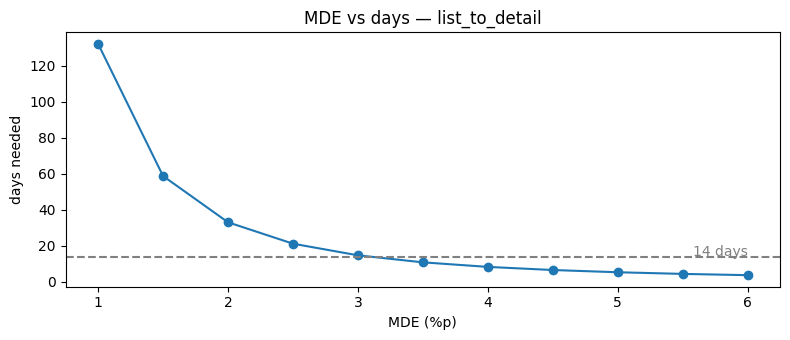

In [11]:
# [1.5-C] 필요한 기간
# 실험 전 데이터에서 대상 사용자의 하루 평균 '분모 세션 수'를 구하고, 그룹당으로 환산하세요.

num_col, den_col = METRICS[PRIMARY]
daily_denominator = target_pre.groupby("day")[den_col].sum().mean()
TRAFFIC_SHARE = 0.5
daily_per_group = daily_denominator * TRAFFIC_SHARE / 2

n_per_group = n_per_group_naive * design_effect
days_needed = n_per_group / daily_per_group
print(f"그룹당 필요한 분모 세션(디자인 효과 반영): {n_per_group:,.0f}")
print(f"그룹당 하루 분모 세션: {daily_per_group:,.0f} → 계산상 {days_needed:.1f}일")

# MDE를 바꾸면 기간이 어떻게 달라지는지
mdes = np.arange(0.01, 0.061, 0.005)
days = [NormalIndPower().solve_power(proportion_effectsize(p0 + m, p0), alpha=ALPHA, power=POWER) * design_effect / daily_per_group for m in mdes]
plt.figure(figsize=(8, 3.5))
plt.plot(mdes * 100, days, marker="o")
plt.axhline(14, ls="--", c="gray"); plt.text(mdes[-1] * 100, 14.5, "14 days", ha="right", color="gray")
plt.xlabel("MDE (%p)"); plt.ylabel("days needed"); plt.title(f"MDE vs days — {PRIMARY}")
plt.tight_layout(); plt.show()

### Q1.5 표본과 기간

1. A/A 테스트 결과 두 그룹의 차이는 유의했나요? 유의하지 않아야 정상인 이유는?
2. 사용자 단위 표준오차가 세션 독립 가정 표준오차보다 큰 이유를 "같은 사람의 세션"이라는 말을 써서 설명하세요.
3. 계산상 필요한 일수와 **최종으로 정한 실험 기간**은 각각 며칠인가요? 계산값보다 길게 잡았다면 그 이유는?
4. MDE를 어떤 근거로 정했나요? (통계가 아닌 **비즈니스 관점**의 근거를 포함)
5. (선택) `PRIMARY`를 `search_to_complete`로 바꿔 다시 계산해보세요. 기간이 어떻게 달라지나요? 이것이 1.3의 지표 역할 선택에 어떤 의미가 있나요?

**답변:**
1. 유의하지 않았다. A 0.4796, B 0.4803, 차이 +0.0007, p=0.93, 신뢰구간 [-0.0145, +0.0159]로 0을 포함했다. 처치가 없으므로 차이가 없어야 정상이고, 유의하면 배정이나 로깅에 문제가 있다는 신호다.
2. 같은 사람의 세션은 전환 성향이 비슷해서 서로 독립이 아니다. 세션을 독립으로 보면 정보량을 과대평가해 표준오차가 작아진다. 사용자 단위로 묶으면 se_naive 0.0061이 se_delta 0.0078로 커지고, 디자인 효과는 1.59다.
3. 계산상 필요한 일수는 5.3일, 최종 기간은 14일이다. 요일 주기(7일 배수)를 포함하고, 신기함 효과를 일별로 보며, 8일차 캠페인 전후 7일씩을 비교하기 위해 길게 잡았다.
4. MDE는 5%p다. promotion과 다른 채널의 격차(약 10%p)의 절반만 줄여도 쿠폰 도입 가치가 있다고 보았고, 쿠폰은 할인 비용이 따르므로 이보다 작은 효과는 이득이 불확실하다. 가설의 기대치(12%p)보다 보수적으로 잡았다.
5. search_to_complete는 같은 상대 변화(MDE 1.3%p)에 약 27일이 걸리고, MDE 1%p면 약 46일이다. list_to_detail은 5.3일이다. 결제완료는 드문 사건이라 표본이 많이 필요하므로, 기간 안에 판정 가능한 list_to_detail을 Primary로, search_to_complete는 가드레일로 둔다. 가드레일의 "유의한 악화 없음"은 검정력이 낮아 "변화 없음이 증명됨"과 같지 않다.

## 1.6 실험 기간 중간에 외부 변화가 생긴다면?

마케팅팀에서 연락이 왔습니다. **실험 8일차부터 promotion 채널 대규모 광고 캠페인이 시작**되어 promotion 유입이 크게 늘어납니다.

1. 이 캠페인은 A그룹과 B그룹에 **똑같이** 영향을 줍니다. 그래도 실험 결과 해석에 문제가 생길까요? 무작위 배정의 성질로 설명하세요.
2. 캠페인으로 새로 들어오는 사용자는 평소 promotion 사용자와 어떻게 다를까요? 어떤 지표의 수준이 8일차 전후로 달라질까요?
3. 이 상황에서 설계를 바꾸거나 분석 계획에 추가할 것이 있다면? (캠페인을 피해 실험을 미루거나 줄이는 선택지도 검토)

**답변:**
1. 큰 문제는 없다. 무작위 배정이면 캠페인이 A와 B에 같은 방식으로 들어오므로, 두 그룹의 차이에는 캠페인이 편향을 만들지 않는다. 다만 일반화에는 한계가 있다. 캠페인 유입 사용자에게 쿠폰 팝업의 효과가 평소 promotion 사용자와 다를 수 있어서, 실험 결과는 "캠페인이 섞인 기간의 promotion 사용자에 대한 효과"로 읽어야 한다.
2. 캠페인으로 새로 들어온 사용자는 구매 의도가 상대적으로 약하고 광고를 보고 들어온 탐색 중심 사용자가 많을 것이다. 따라서 8일차 전후로 두 그룹 모두 list_to_detail과 search_to_complete의 수준이 떨어지고, 세션 수(분모)는 늘어난다. 이 수준 변화는 A와 B에 똑같이 나타나서 비교는 유효하다.
3. 실험을 미루거나 줄이지 않고 14일을 유지한다. 캠페인 전 7일만 쓰면 요일·신기함 효과를 보기 어렵고, 캠페인 이후로 미루면 결정이 늦어진다. 대신 분석 계획에서 구간별 분석은 결과를 보고 판정을 바꾸기 위한 것이 아니라 효과가 왜 달라졌는지 해석하는 보조 분석으로만 쓴다.

## 1.7 사전 판정 규칙

결과를 보기 **전에** 아래 표를 채우세요. Part 2에서는 이 표대로 판정합니다.

| 상황 | 판정 |
|---|---|
| 데이터 품질(SRM) 검정 p < 0.001 |결과 해석을 중단하고 효과 판정을 하지 않는다. 원인을 찾아 고친 뒤 재실험한다. |
| Primary가 유의하게 개선 + 모든 Guardrail 유의한 악화 없음 |배포. 단, 일별 효과가 초반에만 몰려 있으면 신기함 효과를 의심하고 배포 전에 추가 관찰한다. |
| Primary가 유의하게 개선 + Guardrail 중 하나라도 유의하게 악화 |배포 보류. 개선 폭과 악화 폭, 쿠폰 비용을 함께 비교하고, 가드레일 악화를 줄인 수정안으로 재실험한다. |
| Primary 유의하지 않음 | 신뢰구간으로 나눈다. 구간 상한이 MDE(5%p)보다 작으면 의미 있는 효과가 없는 것이므로 종료한다. 상한이 MDE 이상이면 정보가 부족한 것이므로 재실험한다.|
| (선택) 그 밖에 미리 정해두고 싶은 규칙 | |

In [12]:
# [1.8] 최종 설계서 — 위에서 정한 값을 그대로 옮기세요. 이 셀이 Part 2의 실험을 결정합니다.

my_design = {
    "idea":           "C",      # "A" | "B" | "C"
    "target":         "promotion",      # "promotion" | "all"
    "unit":           "user",      # "user" | "session"
    "primary_metric": PRIMARY,
    "guardrails":     ["revenue_per_search", "search_to_complete"],      # 예: ["search_to_complete", "detail_to_room"]
    "secondary":      [],
    "alpha":          ALPHA,
    "power":          POWER,
    "mde_abs":        MDE,
    "traffic_share":  TRAFFIC_SHARE,
    "duration_days":  14,        # 1.5에서 정한 최종 기간 (3~42)
    "stopping":       "fixed",      # "fixed": 정한 기간까지 / "peek": 매일 확인하다 유의하면 중단
}
my_design

{'idea': 'C',
 'target': 'promotion',
 'unit': 'user',
 'primary_metric': 'list_to_detail',
 'guardrails': ['revenue_per_search', 'search_to_complete'],
 'secondary': [],
 'alpha': 0.05,
 'power': 0.8,
 'mde_abs': 0.05,
 'traffic_share': 0.5,
 'duration_days': 14,
 'stopping': 'fixed'}

---
# Part 2. 실행과 판정

여기서부터는 Part 1을 수정하지 마세요. 아래 셀을 실행하면 **여러분의 설계대로** 실험이 진행됩니다.

In [13]:
exp = run_experiment(my_design, SEED)
display(exp.head())

실험 기간: 2026-03-02 ~ 2026-03-15 (14일)
실험에 노출된 사용자: 5,931명 / 세션: 17,168개
참고: 실험 8일차(2026-03-09)부터 마케팅팀의 promotion 채널 대규모 광고 캠페인이 시작됐습니다.


,session_id,user_id,channel,device,user_type,day,session_start,group,search,list_view,detail_view,room_select,checkout,payment_complete,payment_method,amount,cancelled,net_amount
0,E00000000,200145,promotion,ios,leisure,1,2026-03-02 11:05:57,B,1,1,0,0,0,0,None,0.0000,0,0.0000
1,E00000001,200148,promotion,web,leisure,1,2026-03-02 18:55:56,B,1,1,1,0,0,0,None,0.0000,0,0.0000
2,E00000002,200478,promotion,android,leisure,1,2026-03-02 11:53:28,B,1,1,1,0,0,0,None,0.0000,0,0.0000
3,E00000003,200479,promotion,android,business,1,2026-03-02 21:25:01,B,1,1,0,0,0,0,None,0.0000,0,0.0000
4,E00000004,200638,promotion,android,leisure,1,2026-03-02 13:10:08,B,1,1,0,0,0,0,None,0.0000,0,0.0000


## 2.1 데이터 품질 — SRM 확인

결과 지표를 보기 전에 **배정 비율이 설계(50:50)대로인지** 먼저 확인합니다.

In [16]:
from scipy.stats import chisquare

# 주석 빈칸: 배정 단위가 사용자이므로, 그룹별 사용자수를 세어야 한다.
counts = exp.groupby("group")["user_id"].nunique()
print(counts)

total = counts.sum()
srm_p = chisquare(counts.values, f_exp=[total * 0.5, total * 0.5]).pvalue
print(f"SRM 검정 p-value: {srm_p:.2e}  →  {'SRM 의심! 결과 해석을 멈추세요' if srm_p < 0.001 else '통과'}")

# 어디서 어긋났는지 보기: 기기별 그룹 사용자 수
display(exp.groupby(["device", "group"])["user_id"].nunique().unstack())

group
A    2967
B    2964
Name: user_id, dtype: int64
SRM 검정 p-value: 9.69e-01  →  통과


group,A,B
device,,
android,1233,1205
ios,1125,1119
web,609,640


### Q2.1
1. SRM 검정 결과는? 통과하지 못했다면, 기기별 표에서 어디가 어긋났나요?
2. SRM이 있을 때 결과를 그대로 믿으면 안 되는 이유는? "어떤 사용자가 빠졌는가"의 관점에서 설명하세요.

**답변:**

1. SRM 검정은 통과했다. 그룹별 사용자 수는 A 2,967명, B 2,964명이고 p-value는 0.969(기준 0.001)다. 기기별 표에서도 android 1,233 대 1,205, ios 1,125 대 1,119, web 609 대 640으로 어긋난 곳이 없다.
2. SRM이 있으면 특정 사용자들이 한쪽 그룹에서만 빠졌다는 뜻이고, 이렇게 되면 두 그룹이 더 이상 같은 조건에서 시작하지 않은 것이다. 예를 들어 B 그룹에서 구형 브라우저 사용자 같은 특정 집단이 사라졌다면, 남은 B 그룹은 원래 구매 성향이 다른 사용자들로 구성되어 처치 효과와 구성 차이가 섞인다. 그러면 지표 차이가 처치 때문인지 빠진 사용자 때문인지 알 수 없으므로 결과를 믿으면 안 된다.

## 2.2 지표 분석

`ratio_test(df, metric)`은 두 가지 표준오차를 함께 보여줍니다.
- `se_naive`, `p_naive`: 세션을 서로 독립인 관측으로 본 계산
- `se_delta`, `p_value`, `ci_low ~ ci_high`: 같은 사용자의 세션끼리 묶어서 계산 (**판정에는 이쪽을 사용**)

In [17]:
# [2.2-A] Primary + Guardrail + Secondary 결과표
metrics_to_check = [my_design["primary_metric"]] + my_design["guardrails"] + my_design["secondary"]

results = pd.DataFrame([ratio_test(exp, m) for m in metrics_to_check])
display(results)

,metric,A,B,diff,rel_diff,ci_low,ci_high,p_value,se_delta,se_naive,p_naive
0,list_to_detail,0.4465,0.4652,0.0187,0.0419,-0.0015,0.0389,0.0694,0.0103,0.0079,0.0183
1,revenue_per_search,"20,715.6532","18,792.5335","-1,923.1197",-0.0928,"-3,946.3053",100.0659,0.0625,"1,032.2565",913.6314,0.0353
2,search_to_complete,0.1187,0.1221,0.0034,0.0284,-0.0078,0.0146,0.5558,0.0057,0.0050,0.4981


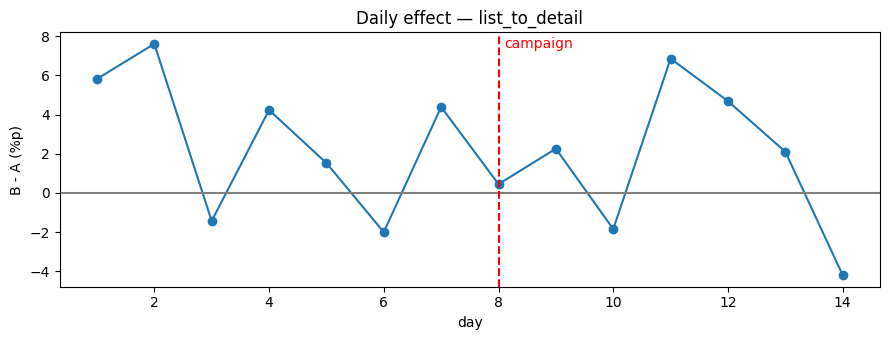

1~7일: diff=+0.0286, 95% CI [+0.0010, +0.0562]
8일~: diff=+0.0145, 95% CI [-0.0088, +0.0378]


In [18]:
# [2.2-B] 일별 Primary 효과 — 신규성 효과와 8일차(캠페인 시작) 전후 확인
num_col, den_col = METRICS[my_design["primary_metric"]]
daily = exp.groupby(["day", "group"]).agg(num=(num_col, "sum"), den=(den_col, "sum")).reset_index()
daily["rate"] = daily["num"] / daily["den"]

# 주석 빈칸: pivot 후 B - A를 계산하면 그날 하루의 ________ 를 볼 수 있다.
daily_diff = daily.pivot(index="day", columns="group", values="rate")
daily_diff["diff"] = daily_diff["B"] - daily_diff["A"]

plt.figure(figsize=(9, 3.5))
plt.plot(daily_diff.index, daily_diff["diff"] * 100, marker="o")
plt.axhline(0, c="gray"); plt.axvline(8, ls="--", c="red"); plt.text(8.1, plt.ylim()[1] * 0.9, "campaign", color="red")
plt.xlabel("day"); plt.ylabel("B - A (%p)"); plt.title(f"Daily effect — {my_design['primary_metric']}")
plt.tight_layout(); plt.show()

# 전반부(1~7일) vs 후반부(8일~) 효과
for name, sub in [("1~7일", exp[exp["day"] <= 7]), ("8일~", exp[exp["day"] >= 8])]:
    r = ratio_test(sub, my_design["primary_metric"])
    print(f"{name}: diff={r['diff']:+.4f}, 95% CI [{r['ci_low']:+.4f}, {r['ci_high']:+.4f}]")

### Q2.2
1. Primary의 효과를 **점추정이 아니라 신뢰구간으로** 한 문장으로 말하세요. (예: "목록 → 상세 전환율이 ○%p에서 ○%p 사이로 올랐다")
2. `se_naive`와 `se_delta` 중 어느 쪽이 더 큰가요? naive로 판정했다면 어떤 위험이 있나요?
3. 일별 그래프에서 효과가 기간 내내 비슷한가요, 아니면 초반에 몰려 있나요? 어떤 의미인가요?
4. Guardrail 지표는 어떻게 나왔나요? "유의한 악화 없음"과 "변화 없음이 증명됨"은 같은 말인가요?
5. A그룹과 B그룹의 Primary 지표 **수준**이 8일차 전후로 어떻게 달라졌나요? 그런데도 A/B 비교가 유효한 이유는?

**답변:**
1. 목록 → 상세 전환율은 -0.15%p에서 +3.9%p 사이로 변했다. 오른 것으로 단정할 수 없고 오르더라도 최대 약 4%p다.
2. se_delta(0.0103)가 se_naive(0.0079)보다 크다. naive로 판정하면 p=0.018로 유의하게 나와 효과가 있다고 잘못 결론 낼 수 있었다. 사용자 단위로 묶으면 p=0.069로 유의하지 않다.
3. 효과는 초반에 몰려 있다. 1,2일차 B와 A 차이가 +5.8%p, +7.6%p였고 이후에는 0 근처에서 등락한다. 1~7일은 +2.9%p(신뢰구간 [+0.1, +5.6]), 8일 이후는 +1.5%p(신뢰구간이 0을 포함)로 줄었다. 팝업의 신기함 효과일 수 있지만 8일차 캠페인도 겹쳐서 원인을 구분할 수 없고, 두 구간의 신뢰구간이 크게 겹치며 일별 변동도 커서 단정하지 않는다.
4. revenue_per_search는 -9.3%(p=0.0625, 신뢰구간 [-3,946, +100])로 유의한 악화는 아니지만 점추정이 크게 나쁘다. search_to_complete는 +0.0034(p=0.56)로 변화가 없었다. "유의한 악화 없음"은 "변화 없음이 증명됨"과 같지 않다. 신뢰구간이 넓어서 매출이 실제로 줄었을 가능성도 배제하지 못한다.
5. 두 그룹 모두 8일차 이후 수준이 내려갔다. A는 0.5036에서 0.4049로, B는 0.5322에서 0.4194로 약 10%p 떨어졌고 하루 세션 수는 약 1,000개에서 약 1,440개로 늘었다. 캠페인으로 구매 의도가 약한 사용자가 들어왔기 때문이다. 무작위 배정이라 캠페인이 A와 B에 똑같이 영향을 주므로 두 그룹의 비교는 유효하다.

## 2.3 판정

1.7의 사전 판정 규칙을 그대로 적용하세요.

- **해당하는 규칙 행:** Primary가 유의하지 않음, 신뢰구간 상한(+3.9%p)이 MDE(5%p)보다 작음
- **판정:** 종료
- **결정 메모 (3~5문장):** 쿠폰 팝업을 보여 준 그룹의 목록 → 상세 전환율은 약 +1.9%p 높았지만, 우연일 가능성을 배제하지 못하는 수준이고 실제 효과는 -0.2%p에서 +3.9%p 사이로 추정된다. 쿠폰이 도입할 가치가 있다고 정한 5%p에는 못 미치므로 이 팝업은 배포하지 않는다.
- **다음 실험 아이디어 (1개):** 쿠폰 팝업은 목록 → 상세 단계가 아니라 앱 진입 시점에 작용한다. 병목 단계 자체를 겨냥하는 아이디어 A가 광고에서 본 할인가와 목록의 가격이 달라 이탈한다는 가설을 직접 검증할 수 있다.

---
# Part 3. 심화 과제 — 아래 중 1개 선택

같은 사용자 데이터로 **설계 한 가지만 바꿔** 다시 실험하고, 결과가 왜 달라졌는지 분석하세요.

| 선택 | 바꿀 것 | 생각해볼 질문 |
|---|---|---|
| **A. 기간과 중단 규칙** | `duration_days`를 7로, 또는 `stopping`을 `"peek"`으로 | 언제 멈췄나? 효과 크기가 어떻게 달라졌나? 왜? |
| **B. 대상 범위** | `target`을 반대로 | 효과 크기와 표준오차가 어떻게 달라졌나? 어느 쪽이 의사결정에 유리한가? |
| **C. 배정 단위** | `unit`을 반대로 | 효과 크기가 왜 달라졌나? 사용자 경험 측면의 문제는? |

### 심화 과제 작성
- 선택한 항목: A. 기간과 중단 규칙
- 바꾼 설계 값: stopping을 "fixed"에서 "peek"으로 바꿨다. 매일 확인하다 p값이 0.05보다 작으면 중단하는 규칙이고, 나머지 설계는 그대로다.
- 원래 결과 vs 바뀐 결과 (핵심 숫자 2~3개):실험은 3일차에 중단되었고 사용자 2,198명, 세션 3,039개가 쓰였다. 계획한 그룹당 2,495세션에 그룹당 약 1,500세션이어서 모자란다.
Primary 효과는 +1.87%p에서 +3.96%p로 약 2배가 되었다. p값은 0.069에서 0.045로 겨우 유의해졌다.
신뢰구간이 [-0.15, +3.89]에서 [+0.08, +7.84]로 넓어졌고 상한이 MDE(5%p)를 넘는다.
- 왜 달라졌는가:원래 일별 효과를 보면 1~2일차가 +5.8%p, +7.6%p로 컸고 3일차부터 0 근처에서 움직였다. 3일차까지 합치면 초반의 큰 효과가 평균을 끌어올려 p값이 처음으로 0.05 밑으로 내려갔고, 그 순간 규칙이 멈췄다. 즉 효과가 가장 부풀려진 시점에서 멈춘 것이다. 표본이 모자란 상태라 신뢰구간도 넓어서, 유의하다는 것과 효과가 크다는 것이 모두 불확실하다. 14일을 다 보면 초반의 신기함이 평균에서 희석되고 효과가 +1.87%p로 내려온다.
- 실무에서 이 교훈을 적용한다면:중단 규칙은 실험 전에 정하고 결과를 보면서 바꾸지 않는다. 중간에 확인해야 한다면 처음부터 sequential testing 같은 방법을 설계에 넣고, 신기함 효과를 줄이기 위해 최소 기간을 1~2주로 잡는다. 이번 사례처럼 조기 중단된 유의한 결과는 효과 크기를 과대추정했을 가능성이 높으므로, 크기는 그대로 믿지 않는다.

In [19]:
# [심화 과제 Skeleton]
alt_design = dict(my_design)
alt_design["stopping"] = "peek"      # 바꿀 설계 하나

alt = run_experiment(alt_design, SEED)
alt_results = pd.DataFrame([ratio_test(alt, m) for m in metrics_to_check])
display(pd.concat({"원래 설계": results.set_index("metric"), "바꾼 설계": alt_results.set_index("metric")}, axis=1))

실험 기간: 2026-03-02 ~ 2026-03-04 (3일 · 중간 확인 규칙으로 조기 종료)
실험에 노출된 사용자: 2,198명 / 세션: 3,039개
참고: 실험 8일차(2026-03-09)부터 마케팅팀의 promotion 채널 대규모 광고 캠페인이 시작됐습니다.


원래 설계                                               \
                             A           B        diff rel_diff      ci_low   
metric                                                                        
list_to_detail          0.4465      0.4652      0.0187   0.0419     -0.0015   
revenue_per_search 20,715.6532 18,792.5335 -1,923.1197  -0.0928 -3,946.3053   
search_to_complete      0.1187      0.1221      0.0034   0.0284     -0.0078   

                                                                      바꾼 설계  \
                    ci_high p_value   se_delta se_naive p_naive           A   
metric                                                                        
list_to_detail       0.0389  0.0694     0.0103   0.0079  0.0183      0.5073   
revenue_per_search 100.0659  0.0625 1,032.2565 913.6314  0.0353 23,961.1147   
search_to_complete   0.0146  0.5558     0.0057   0.0050  0.4981      0.1397   

                                                                            \
                             B        diff rel_diff      ci_low    ci_high   
metric                                                                       
list_to_detail          0.5469      0.0396   0.0781      0.0008     0.0784   
revenue_per_search 21,830.1083 -2,131.0064  -0.0889 -6,750.3006 2,488.2877   
search_to_complete      0.1380     -0.0016  -0.0117     -0.0265     0.0232   

                                                          
                   p_value   se_delta   se_naive p_naive  
metric                                                    
list_to_detail      0.0454     0.0198     0.0189  0.0358  
revenue_per_search  0.3659 2,356.8260 2,301.5647  0.3545  
search_to_complete  0.8977     0.0127     0.0126  0.8967

---
# Part 4. 회고

- 설계 단계에서 가장 고민했던 결정과 그 이유:아이디어 선택(C)이었다. 디자인팀의 근거는 A와 B가 목록 화면의 문제를 직접 겨냥하는 것처럼 보였지만 그 이탈 이유는 데이터로 확인된 것이 아니었고, C는 promotion 사용자 전체에 적용할 수 있다고 판단했다. 다만 C의 팝업이 목록 → 상세 단계가 아니라 첫 진입 시점에 뜬다는 점이 약한 고리라서, 가설에서 이 경로를 어떻게 설명할지가 어려웠다. 트래픽 비율은 쿠폰 비용 위험을 줄이려고 0.5로 정했다.
- 결과를 보고 "설계를 바꾸고 싶다"고 느낀 순간이 있었나요? 있었다면 무엇이었나요?Part 3에서 peek으로 바꾼 결과가 3일차에 p=0.045로 유의하게 나왔을 때다. 14일 결과(p=0.069)는 유의하지 않았는데 3일차 결과는 유의해서, 조기 결과를 믿고 배포하고 싶은 쪽으로 마음이 쏠리는 것을 직접 확인했다. 사전 규칙이 없으면 결과를 보고 규칙을 바꾸고 싶어진다는 점을 체감했다.
- 진단 결과를 실험으로 검증해보며 새로 알게 된 점 (다음 그로스 세션에서는 이런 진단을 직접 하는 법을 배웁니다):진단(promotion 전환율이 낮다)과 처방(쿠폰 팝업)이 이어지는 경로가 약하면 실험 결과도 약하게 나온다는 점이다.
- 가장 어려웠던 부분:MDE를 정하는 일이었다. 통계 계산은 정해진 절차가 있지만, 몇 %p 이상이면 쿠폰 비용을 감수할 가치가 있는지는 비즈니스 판단이어서 근거를 만들기 어려웠다.

---
# Part 5. 제출 전 체크리스트

- [ ] Q0에서 실험이 필요한 처방과 바로 고쳐야 하는 처방을 구분했는가?
- [ ] 가설에 바꾸는 것, 행동 메커니즘, 지표와 방향이 모두 있는가?
- [ ] 모든 지표의 분자 / 분모 / Grain / Window를 명시했는가?
- [ ] 배정 단위와 분석 단위의 차이를 고려했는가? (A/A 테스트, 디자인 효과)
- [ ] MDE를 비즈니스 근거로 정했고, 기간을 계산값보다 짧지 않게 정했는가?
- [ ] 판정 규칙을 결과를 보기 전에 정했고, 결과를 본 뒤 Part 1을 수정하지 않았는가?
- [ ] SRM을 가장 먼저 확인했는가?
- [ ] 효과를 신뢰구간으로 말했는가?
- [ ] 기술블로그에 옮길 설계서, 그래프, 결정 메모를 정리했는가?
- [ ] 마지막 셀에 AI 활용 방법과 대화 내역을 붙였는가?

---
# Part 6. 생성형 AI 활용 방법 + 대화 내역 (필수)

AI를 사용했다면 아래를 작성하고, **대화 내역을 붙여넣으세요.** 사용하지 않았다면 "사용하지 않음"이라고 적어주세요.

1. 어느 문항에서, 어떤 목적으로 AI를 썼나요? 챗지피티와 클로드를 노트북 구조 설명, 코드 빈칸 채우기,답변 초안 작성, 수치 계산 확인에 사용하였다.
2. AI의 답 중 **본인 데이터로 확인해보니 틀렸거나 맞지 않았던 것**이 있었나요?처방 ①을 “promotion 전환율 개선”으로 잘못 가정하였다..
3. 이번 과제에서 AI에게 맡길 수 없었던, **사람이 직접 판단해야 했던 결정**은 무엇이었나요? 직접 판단한 결정은 아이디어 선택(C), 트래픽 비율(0.5), 최종 기간(14일), 판정 규칙 확정, 그리고 가설의 기대 효과(0.60)였다. 쿠폰 비용 대비 가치를 어떻게 볼지는 AI가 대신 판단할 수 없는 부분이었다.

### 대화 내역
( Q0. 무엇을 A/B 테스트할 것인가?
처방 ①과 ② 중 A/B 테스트가 필요한 것은 무엇인가요? 나머지 하나는 어떻게 배포·검증하는 게 맞을까요?
처방 ①을 A/B 테스트로 검증하면 어떤 문제가 생기나요? (사용자 경험, 법·윤리, 결정에 쓸 수 있는 정보 관점에서)
"A/B 테스트를 하지 않는다"고 해서 아무것도 측정하지 않는 것은 아닙니다. 처방 ①을 배포할 때 무엇을 모니터링해야 할까요? AB테스트가 필요할 조건이 뭘까
핵심은 처방 ①은 A/B 테스트보다 안전성과 부작용을 모니터링하면서 배포하고, 처방 ②는 A/B 테스트로 효과를 비교하는 것이 적절하다는 거야.

다만 정확한 처방 ①·②의 내용이 현재 메시지에는 없어서, 아래는 일반적인 판단 기준으로 정리할게.

Q0. 무엇을 A/B 테스트할 것인가?
1. 처방 ①과 ② 중 A/B 테스트가 필요한 것은?
처방 ①: 사용자에게 피해를 주거나 법적·윤리적 문제가 발생할 가능성이 있는 처방이라면 A/B 테스트하지 않는다. 전체 적용 또는 제한적 단계 배포 후 안전성을 모니터링한다.

처방 ②: 여러 대안 중 어떤 것이 사용자 경험이나 서비스 성과를 더 개선하는지 비교해야 한다면 A/B 테스트한다.

2. 처방 ①을 A/B 테스트하면 어떤 문제가 생기는가?
①을 일부 사용자에게만 적용하고 나머지에게는 기존 방식을 유지하면 다음 문제가 발생할 수 있다.

사용자 경험: 일부 사용자에게 의도적으로 불리하거나 위험한 경험을 제공할 수 있다.

법·윤리: 사용자 동의, 차별, 개인정보 보호 등 법적·윤리적 문제가 발생할 수 있다.

의사결정: 피해가 발생할 수 있는 처방은 효과의 우열을 비교하는 것보다 피해 발생 여부와 안전성을 확인하는 것이 우선이다.

3. A/B 테스트 없이 처방 ①을 배포한다면 무엇을 모니터링해야 하는가?
A/B 테스트를 하지 않는다고 성과 측정을 하지 않는 것은 아니다.

안전성: 오류율, 피해 발생률, 이상 행동 발생률

사용자 반응: 불만 접수, 이탈률, 고객 문의 증가

서비스 품질: 처리 성공률, 응답 지연, 시스템 장애

공정성: 특정 사용자 집단에 피해가 집중되는지 여부

처방 ①은 배포 전 기준선을 확보하고, 배포 후 지표를 지속적으로 관찰하며 문제가 발생하면 즉시 롤백할 수 있도록 해야 한다.

A/B 테스트가 필요한 조건
시험 답안으로는 다음 문장을 기억하면 좋아.

A/B 테스트는 다음 조건을 만족할 때 실시한다.

비교할 수 있는 복수의 대안이 존재한다.

대안 간 효과의 차이가 불확실하다.

무작위로 집단을 나누어도 사용자에게 피해나 불이익이 발생하지 않는다.

효과를 측정할 수 있는 명확한 지표가 존재한다.

실험 결과가 실제 의사결정에 활용될 수 있다.

한 줄 핵심

효과의 우열을 비교하는 문제 → A/B 테스트

안전성·법적 준수·필수적인 개선 문제 → 단계적 배포 및 모니터링

단, 처방 ①과 ②의 실제 내용이 담긴 화면이나 자료를 보내주면, 이 기준을 적용해서 과제에 맞는 정답으로 구체화해 줄게.


PDF로 변환

list_sessions	detail_sessions	list_to_detail
channel
promotion	52906	25408	0.4802
paid_search	69715	40094	0.5751
organic	97392	57318	0.5885
referral	38385	23229	0.6052
svg

에서 처방1을 ab 테스트하면 어떤 윤리적 문제가 생길까

…
이 데이터에서 처방 ①이 promotion 채널의 상세 페이지 진입률(list_to_detail)을 개선하는 것이라면, A/B 테스트에서 발생할 수 있는 윤리적 문제는 다음과 같아.

1. 어떤 윤리적 문제가 발생하는가?
현재 promotion 채널의 상세 페이지 진입률은 **48.02%**로, 다른 채널(57.51~60.52%)보다 현저히 낮아.

이 상황에서 처방 ①을 A/B 테스트하면 다음 문제가 생길 수 있어.

사용자 경험의 불평등: promotion 유입 사용자 중 일부에게만 개선된 화면이나 기능을 제공하고, 나머지 사용자에게는 낮은 전환율을 보이는 기존 경험을 의도적으로 유지하게 된다.

기회 불평등: 동일한 서비스에 접근한 사용자임에도 실험군과 대조군에 따라 정보 접근성이나 예약 기회에 차이가 발생할 수 있다.

사용자 신뢰 저하: 서비스가 개선 가능성을 알고 있으면서도 실험을 위해 일부 사용자에게 기존의 불편한 경험을 제공한다는 문제가 발생할 수 있다.

2. 과제 제출용 답안
promotion 채널의 상세 페이지 진입률은 48.02%로 다른 채널에 비해 현저히 낮다. 이 문제를 해결하기 위한 처방 ①을 A/B 테스트하면, 일부 사용자에게만 개선된 경험을 제공하고 나머지 사용자에게는 기존의 낮은 품질의 경험을 유지하게 된다는 윤리적 문제가 발생할 수 있다. 특히 사용자가 개선된 서비스를 이용할 기회를 제한하고, 실험군과 대조군 사이에 서비스 이용 경험의 불평등을 초래할 수 있다. 따라서 사용자에게 불필요한 불이익을 주는 실험보다는 처방을 전체 적용하거나 단계적으로 배포한 후 개선 효과와 부작용을 모니터링하는 것이 적절하다.

다만 중요한 구분이 있어. 전환율이 낮다는 사실만으로 A/B 테스트가 비윤리적인 것은 아니야. 기존 화면이 사용자에게 실질적인 피해를 주거나, 개선이 명백히 필요한데도 일부 사용자에게 의도적으로 불리한 경험을 제공하는 경우 윤리적 문제가 커지는 거야. 단순히 전환율 개선을 위한 UI 변경이라면 일반적인 A/B 테스트도 충분히 가능해.


PDF로 변환
Part 0. 상황 브리핑 — 무엇을 실험할 것인가?
2026년 2월, 분석팀이 퍼널을 채널별로 쪼개 보다가 이런 메모를 남겼습니다.

분석팀 메모 promotion(광고·프로모션) 채널로 들어온 사용자는 목록 → 상세 전환율이 다른 채널보다 10%p가량 낮다. 다른 퍼널 단계는 채널 간 차이가 거의 없다. 최근에 갑자기 나빠진 게 아니라 원래부터 낮은 상태다.

같은 주에 QA팀에서도 이슈가 올라왔습니다.

QA팀 이슈 일부 숙소의 상세 페이지 가격이 세금·봉사료가 빠진 금액으로 표시되고, 결제 화면에서야 최종 금액이 나온다. 총액 표시 의무 위반 소지가 있다.

팀은 두 가지 처방을 준비했습니다.

처방 ① 상세 페이지 가격 표시 오류 수정 (총액 표시)
처방 ② promotion 유입 사용자의 목록 → 상세 전환을 높이는 화면 개선
먼저 실험 전 데이터로 분석팀 메모가 맞는지 확인하세요.이게처방이야

…
아, 이제 처방 ①과 ②의 차이가 명확해졌어. 이 사례에서는 처방 ①은 A/B 테스트를 하면 안 되는 쪽이고, 처방 ②는 A/B 테스트가 필요한 쪽이야.

특히 윤리적 문제뿐 아니라 법적 문제까지 구분해서 답하면 좋아.

1. 먼저 실험 전 데이터로 분석팀 메모 확인
채널

목록 → 상세 전환율

Organic

58.85%

Paid Search

57.51%

Promotion

48.02%

Referral

60.52%

Promotion은 가장 높은 Referral(60.52%)보다 약 12.50%p 낮음.

다른 채널과 비교해도 약 9.49~12.50%p 낮음.

다른 퍼널 단계는 채널 간 차이가 거의 없으므로 목록 → 상세 단계에 문제가 집중되어 있음.

분석팀 메모 타당
따라서 Promotion 채널의 목록 → 상세 전환율이 다른 채널보다 현저히 낮다는 분석팀의 판단은 데이터와 일치해.

2. 처방 ①과 ②의 A/B 테스트 여부
구분

처방 ①

처방 ②

내용

가격 표시 오류 수정

Promotion 화면 개선

목적

법적 의무 준수 및 사용자 보호

전환율 개선

A/B 테스트

부적절

적절

배포 방법

전체 사용자에게 즉시 수정 적용

실험군·대조군 무작위 배정

3. 처방 ①을 A/B 테스트하면 발생하는 문제
① 법적 문제

- 총액 표시 의무 위반 소지가 있다는 사실을 알고도 일부 사용자에게 잘못된 가격을 계속 표시하면 법적 문제가 발생할 수 있음.

② 윤리적 문제

실험군에는 정확한 총액을 보여주고 대조군에는 세금·봉사료가 빠진 가격을 보여주는 것은 사용자에게 불공정함.

사용자가 실제 결제 금액을 사전에 정확히 알지 못해 합리적인 구매 결정을 내릴 권리를 침해할 수 있음.

③ 의사결정 문제

처방 ①은 어느 화면이 전환율을 더 높이는지 알아보는 실험이 아님.

법적·윤리적으로 잘못된 상태를 유지하면서 효과를 비교할 이유가 없음.

4. 처방 ①은 어떻게 검증하는가?
A/B 테스트 대신 전체 적용 후 다음 지표를 모니터링해.

가격 표시 오류 발생 건수

상세 페이지와 결제 페이지의 가격 불일치율

가격 관련 고객 불만 및 환불 건수

총액 표시 적용률

5. 최종 과제 답안
핵심 결론

처방 ①: 법적 의무 및 사용자 보호와 관련된 필수 수정이므로 A/B 테스트 없이 전체 배포하고 모니터링한다.

처방 ②: 개선 효과가 불확실하고 대안 간 성과 비교가 필요하므로 A/B 테스트를 진행한다.

시험에서 기억할 포인트:

A/B 테스트는 단순히 두 가지 방법을 비교하는 도구가 아니라, 비교 실험을 해도 되는 상황에서 효과의 차이를 검증하는 도구야.

이 사례의 핵심은 개선 효과를 검증해야 하는 문제와 반드시 바로잡아야 하는 문제를 구분하는 것이야.


PDF로 변환
. 트래픽 투입 비율 (traffic_share, 0~1)
대상 사용자 중 몇 %를 실험에 넣을까요? 100%가 아니라면 이유는?어떤 비율이 가장 무난해?

처방 ②의 A/B 테스트라면 초기에는 50%(0.5)를 추천해.

실험군: 25%

대조군: 25%

나머지 50%: 기존 서비스 유지

다만 traffic_share가 전체 사용자 중 실험에 투입하는 비율이라면 0.5로 설정하는 거야.

왜 50%가 무난할까?

실험군과 대조군에 충분한 트래픽을 확보할 수 있음.

나머지 50%는 기존 서비스를 유지해 실험 위험을 제한할 수 있음.

실험 결과를 확인한 후 점진적으로 투입 비율을 높일 수 있음.

과제 제출용 답변

초기 트래픽 투입 비율은 50%로 설정한다. 실험군과 대조군에 각각 25%씩 무작위 배정하여 비교에 필요한 데이터를 확보하고, 나머지 50%는 기존 서비스를 유지하여 실험에 따른 잠재적 위험을 최소화한다. 실험 결과가 안정적이면 투입 비율을 점진적으로 확대한다.

참고로 실제 실험에서는 통계적 검정력과 필요한 표본 크기를 먼저 확인해야 해. 50%가 항상 최적이라는 뜻은 아니야.


PDF로 변환
# [1.5-A] Power Analysis

PRIMARY = "__BLANK_5__"            # 1.3에서 정한 Primary 지표 키
p0 = baseline[PRIMARY]             # 기준값
MDE = __BLANK_6__                  # 최소 탐지 효과 (절대값, 예: 0.03 = 3%p)
ALPHA = 0.05
POWER = __BLANK_7__

# 주석 빈칸: proportion_effectsize는 두 비율의 차이를 ________ 로 변환한다. (검정력 계산 함수가 받는 입력 형태)
es = proportion_effectsize(p0 + MDE, p0)

# 주석 빈칸: solve_power는 alpha, power, effect size가 주어졌을 때 ________ 를 구한다.
n_per_group_naive = NormalIndPower().solve_power(effect_size=es, alpha=ALPHA, power=POWER, ratio=1, alternative="two-sided")
print(f"기준값 {p0:.4f}, MDE {MDE:+.3f} → 그룹당 필요한 분모 세션 수(독립 가정): {n_per_group_naive:,.0f}")
블랭크5는 list to detial 맞지 블랭크 6,7에는 뭘넣어야해
맞아! **BLANK_5는 list_to_detail**이 맞아. 처방 ②가 목록 → 상세 전환율 개선이기 때문이야.

나머지는 다음과 같이 입력하면 돼.

# [1.5-A] Power Analysis

PRIMARY = "list_to_detail"
p0 = baseline[PRIMARY]
MDE = 0.03
ALPHA = 0.05
POWER = 0.80

빈칸별 정답
빈칸

입력값

의미

BLANK_5

"list_to_detail"

Primary 지표

BLANK_6

0.03

최소 탐지 효과 3%p

BLANK_7

0.80

검정력 80%

왜 이렇게 설정할까?
MDE = 0.03: 기존 전환율 48.02%에서 최소 3%p 상승한 51.02%를 탐지하고 싶다는 의미야.

POWER = 0.80: 실제로 3%p의 효과가 존재한다면 이를 통계적으로 발견할 확률을 80%로 설정하는 거야.

ALPHA = 0.05: 실제 효과가 없는데 있다고 잘못 판단할 확률을 5%로 제한해.

추천 설정 MDE = 0.03, POWER = 0.80

참고로 MDE 3%p는 통계적으로 정해지는 값이 아니라, 비즈니스적으로 의미 있는 최소 개선 폭을 정하는 값이야. 과제에서 별도 기준이 없다면 이 설정으로 시작하면 무난해.

이 초안에서 네가 정해야 할 것이 있다.

0.5로 갈지 1.0으로 갈지: 1.0이면 MDE 3%p도 7.3일이면 되어 더 짧게 끝난다. 대신 쿠폰 비용 위험을 전체에 노출한다. 0.5도 신기함 효과와 요일 효과를 보려면 어차피 14일 정도는 돌려야 해서 큰 손해는 아니다. 기간 때문에 1.0을 고르는 것보다 위험 때문에 0.5를 고르는 쪽이 설계 근거가 뚜렷하다고 본다.
1.5-C 셀에 TRAFFIC_SHARE = 1.0이 미리 들어 있다. 0.5로 정하면 그 값도 0.5로 바꿔야 한다. 1.8에서도 같은 변수를 쓴다.

밀려 있는 것이 둘 있다. 1.2 가설의 0.60을 그대로 둘지, 1.3의 Primary와 가드레일을 어떻게 할지다. 1.4-C의 기간 계산도 Primary가 list_to_detail이라는 가정으로 했으니, 1.3에서 확정되어야 한다. 다음에는 1.3부터 정리하자.

0.5로 가자
주석 빈칸 1: proportion_effectsize는 두 비율의 차이를 **표준화된 효과 크기(Cohen’s h)**로 변환한다.
주석 빈칸 2: solve_power는 그룹당 필요한 표본 크기를 구한다.
python
PRIMARY = "list_to_detail"
MDE = 0.05
POWER = 0.8

실행하면 나오는 값: 기준값 0.4802, MDE +0.050이면 그룹당 필요한 분모 세션 수는 약 1,570개다. 내 계산(독립 가정)과 대조해서 비슷하면 맞다.

이 숫자는 세션을 독립 관측으로 본 값이다. 1.5-B에서 디자인 효과를 곱하면 약 2,500개로 늘어난다(아까 A/A로 본 값은 약 1.6배). 1.5-C에서 기간으로 환산할 때 이 값이 쓰인다.

MDE를 0.05로 확정할지, 3%p나 4%p로 바꿀지 정해 줘. 그리고 1.3 지표 표가 아직 비어 있다. Primary를 list_to_detail로 확정하면 1.5-B와 1.5-C 칸은 바로 이어서 채울 수 있다.
1.7 사전 판정 규칙
결과를 보기 전에 아래 표를 채우세요. Part 2에서는 이 표대로 판정합니다.

상황    판정
데이터 품질(SRM) 검정 p < 0.001    
Primary가 유의하게 개선 + 모든 Guardrail 유의한 악화 없음    
Primary가 유의하게 개선 + Guardrail 중 하나라도 유의하게 악화    
Primary 유의하지 않음    
(선택) 그 밖에 미리 정해두고 싶은 규칙1.7 초안이다. 판정 용어는 2.3의 선택지(배포 / 배포 보류 / 재실험 / 종료)에 맞췄다.

상황	판정
데이터 품질(SRM) 검정 p < 0.001	결과 해석을 중단하고 효과 판정을 하지 않는다. 원인을 찾아 고친 뒤 재실험한다.
Primary가 유의하게 개선 + 모든 Guardrail 유의한 악화 없음	배포. 단, 일별 효과가 초반에만 몰려 있으면 신기함 효과를 의심하고 배포 전에 추가 관찰한다.
Primary가 유의하게 개선 + Guardrail 중 하나라도 유의하게 악화	배포 보류. 개선 폭과 악화 폭, 쿠폰 비용을 함께 비교하고, 가드레일 악화를 줄인 수정안으로 재실험한다.
Primary 유의하지 않음	신뢰구간으로 나눈다. 구간 상한이 MDE(5%p)보다 작으면 의미 있는 효과가 없는 것이므로 종료한다. 상한이 MDE 이상이면 정보가 부족한 것이므로 재실험한다.
그 밖의 규칙	판정은 14일 전체 기준으로만 한다. 중간에 결과를 보고 멈추지 않는다(fixed). 캠페인 전후 구간 분석은 해석용 보조 분석이고 판정에는 쓰지 않는다.

용어 기준도 같이 정해 두면 좋다. "유의하게 개선"은 ratio_test의 p_value가 0.05보다 작고 diff가 양수인 경우다. "유의하게 악화"는 가드레일 지표의 p_value가 0.05보다 작고 악화 방향인 경우다. 이 기준을 표 아래에 한 줄로 적어 두면 결과를 본 뒤 기준을 바꿨다는 의심을 피할 수 있다.

네가 판단해서 바꿀 수 있는 곳은 세 군데다.

둘째 행의 단서: "신기함 효과가 의심되면 추가 관찰"은 내가 넣은 규칙이다. 일별 효과 그래프가 보조 분석이라는 5행과 충돌하지 않는지 봐 줘. 충돌이 걱정되면 이 단서를 빼도 된다.
셋째 행의 엄격함: 가드레일이 유의하게 나빠지면 무조건 보류한다는 쪽으로 썼다. 쿠폰은 매출을 직접 깎을 수 있어서 보수적으로 두었는데, 악화가 작으면 배포하겠다는 쪽이 낫다면 바꿔도 된다.
넷째 행의 종료와 재실험 구분: 신뢰구간 상한과 MDE를 비교하는 규칙은 세션의 퀴즈 1과 같은 논리다. 이대로 가도 되는지 확인해 줘.

이 표를 확정하면 1.8 최종 설계서로 넘어갈 수 있다. 필요한 값은 idea, target, unit, guardrails, duration_days, stopping이고, 지금까지의 결정을 옮기면 된다. 1.8 셀을 보내 주면 같이 채우겠다.
group
A    2967
B    2964
Name: user_id, dtype: int64
SRM 검정 p-value: 9.69e-01  →  통과
group    A    B
device        
android    1233    1205
ios    1125    1119
web    609    640

SRM은 통과했다. A 2,967명, B 2,964명으로 p-value가 0.969라서 배정 비율에 문제가 없다. 기기별로도 어긋남이 없다. 차이가 가장 큰 web도 609 대 640이라서 무작위 변동 범위 안이다. 1.7의 첫 행에 해당하지 않으므로 효과 판정으로 넘어간다.
)